# Experiment 7a — MLP diagnostic: do non-tree residuals decorrelate from LightGBM-MAE?

This notebook answers **one** question, and the answer is decision-shaped:

> On the same 52 features used by LightGBM-MAE in exp-5.1, with the same 3-fold
> rolling-origin CV, does a small MLP-MAE produce out-of-fold residuals
> with Pearson `r < 0.85` against the LightGBM-MAE residuals?

Why this matters: experiment-6 showed `r(LGBM-MAE, XGB-MAE) = 0.9955` —
two boosters on identical features are essentially the same function. The path to
beating the 14.78 CV floor requires either different features or a different
**model class** (Phase 6.7 of `../APPROACH.md`). This notebook is the cheapest
possible test of the model-class hypothesis: if even an MLP shares the trees'
errors at this correlation level, the saturation is in the *features*, not in
the architecture, and no neural net is going to fix it on this feature set.

**Read `README.md` in this directory first** — it has the decision rules and the
rationale for every design choice below.


---
## §0. Configuration

Mirrors `experiment-5/kp-experiment-5-1.ipynb` §0 exactly, then adds the MLP-specific
config in the second half. Anything you might want to tweak lives in this one cell.


In [1]:
from pathlib import Path

# ── Paths ─────────────────────────────────────────────────────────────────────
# Kaggle paths (default — uncomment LOCAL block below if running locally):
DATA_DIR     = Path("/kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data")
OUTPUT_DIR   = Path("/kaggle/working")
# Local paths:
# DATA_DIR     = Path("../data")
# OUTPUT_DIR   = Path(".")

TRAIN_PATH     = DATA_DIR / "train.csv"
VAL_INPUT_PATH = DATA_DIR / "validation_input.csv"
VAL_INDEX_PATH = DATA_DIR / "forecast_index_validation.csv"

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED         = 42
N_FOLDS      = 3
EVAL_HORIZON = 336      # 14-day forecast window (hours)

# ── Feature config — IDENTICAL to exp-5.1 ────────────────────────────────────
DOMAIN_FEAT_COLS = [
    "workload_intensity", "demand_forecast", "upstream_quality_forecast",
    "promotion_intensity", "shock_risk", "maintenance_known",
    "unit_reliability_forecast", "queue_pressure_forecast",
    "network_pressure_forecast", "event_load_forecast",
    "service_irregularity_risk_forecast",
]
TIME_COLS = ["hour_sin", "hour_cos", "dow_sin", "dow_cos",
             "doy_sin", "doy_cos", "is_weekend"]

TOP_DOM    = ["queue_pressure_forecast", "network_pressure_forecast",
              "workload_intensity", "shock_risk", "event_load_forecast"]
TOP3_ROLL  = TOP_DOM[:3]
LAGS_DOM   = [1, 24]
LEADS_DOM  = [1, 24]
ROLL_WINS  = [6, 24]

# ── LightGBM baseline (exp-5.1's BASELINE_LGBM, untuned — within-noise per exp-5 §5) ──
BASELINE_LGBM = dict(
    n_estimators=600, learning_rate=0.03, num_leaves=63,
    subsample=0.8, colsample_bytree=0.8, min_child_samples=50,
    reg_lambda=1.0, verbose=-1,
)

# ── MLP config — new for this experiment ─────────────────────────────────────
MLP_HIDDEN          = [256, 256, 128]
MLP_DROPOUT         = 0.2
MLP_EMBED_DIM       = 16           # per-series learned embedding dim
MLP_BATCH           = 1024
MLP_LR              = 1e-3
MLP_WEIGHT_DECAY    = 1e-4
MLP_EPOCHS          = 30           # cosine schedule length
MLP_EARLY_STOP      = 5            # patience on val WAPE
MLP_SEEDS           = [42, 101, 202]  # 3 seeds (full pipeline uses 5; 3 is enough for diagnostic)

# ── Decision thresholds — stated up front, NOT after seeing the result ───────
R_STRONG_DIVERSITY  = 0.85         # r < this → green light for ensemble + TiDE
R_FEATURE_BOUND     = 0.95         # r > this → halt DL track on this feature set

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"DATA_DIR    = {DATA_DIR}")
print(f"OUTPUT_DIR  = {OUTPUT_DIR}")
print(f"CV folds    : {N_FOLDS}, horizon: {EVAL_HORIZON}h")
print(f"MLP arch    : {MLP_HIDDEN}, dropout {MLP_DROPOUT}, embed_dim {MLP_EMBED_DIM}")
print(f"MLP train   : batch {MLP_BATCH}, lr {MLP_LR}, weight_decay {MLP_WEIGHT_DECAY}, "
      f"epochs {MLP_EPOCHS} (early stop {MLP_EARLY_STOP}), seeds {MLP_SEEDS}")
print(f"Decision    : r < {R_STRONG_DIVERSITY} → strong diversity; "
      f"r > {R_FEATURE_BOUND} → feature-bound saturation")


DATA_DIR    = /kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data
OUTPUT_DIR  = /kaggle/working
CV folds    : 3, horizon: 336h
MLP arch    : [256, 256, 128], dropout 0.2, embed_dim 16
MLP train   : batch 1024, lr 0.001, weight_decay 0.0001, epochs 30 (early stop 5), seeds [42, 101, 202]
Decision    : r < 0.85 → strong diversity; r > 0.95 → feature-bound saturation


---
## §1. Setup & Data Loading

Same data loading as `kp-experiment-5-1.ipynb` §1. Adds the PyTorch device check
(GPU if available, CPU fallback). Sets all relevant seeds.


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import RobustScaler

np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"  GPU: {torch.cuda.get_device_name(0)}")

def wape(y_true, y_pred, eps=1e-8):
    return np.sum(np.abs(np.asarray(y_true) - np.asarray(y_pred))) / \
           (np.sum(np.abs(y_true)) + eps) * 100

# Load
train_df  = pd.read_csv(TRAIN_PATH,     parse_dates=["timestamp"])
val_input = pd.read_csv(VAL_INPUT_PATH, parse_dates=["timestamp"])
val_index = pd.read_csv(VAL_INDEX_PATH, parse_dates=["timestamp"])

# Stable series_id → integer code (sorted alphabetically so it is reproducible)
sid_to_code = {sid: i for i, sid in enumerate(sorted(train_df["series_id"].unique()))}
N_SERIES = len(sid_to_code)

print(f"train_df:  {train_df.shape}")
print(f"val_input: {val_input.shape}")
print(f"# series:  {N_SERIES}")


PyTorch device: cuda
  GPU: Tesla T4
train_df:  (414720, 25)
val_input: (32256, 24)
# series:  96


---
## §2. Feature Engineering — identical to exp-5.1

This cell is a verbatim copy of `experiment-5/kp-experiment-5-1.ipynb` §2. We want
the LightGBM baseline reproduction in §4 to land exactly where exp-5.1 landed, and
we want the MLP to see exactly the same features the trees saw. Any deviation here
would conflate "different model class" with "different feature view" — defeating
the diagnostic.


In [3]:
def impute_domain_features(df, cols):
    df = df.sort_values(["series_id", "timestamp"]).copy()
    df[cols] = df.groupby("series_id", group_keys=False)[cols].transform(
        lambda x: x.ffill().bfill()
    )
    return df

def add_time_features(df, time_col="timestamp"):
    df = df.copy()
    t = pd.to_datetime(df[time_col])
    df["hour_sin"]   = np.sin(2 * np.pi * t.dt.hour / 24)
    df["hour_cos"]   = np.cos(2 * np.pi * t.dt.hour / 24)
    df["dow_sin"]    = np.sin(2 * np.pi * t.dt.dayofweek / 7)
    df["dow_cos"]    = np.cos(2 * np.pi * t.dt.dayofweek / 7)
    df["doy_sin"]    = np.sin(2 * np.pi * t.dt.dayofyear / 365)
    df["doy_cos"]    = np.cos(2 * np.pi * t.dt.dayofyear / 365)
    df["is_weekend"] = (t.dt.dayofweek >= 5).astype(float)
    return df

def add_temporal_features(df, lag_cols, roll_cols, lags, leads, windows):
    df = df.copy().sort_values(["series_id", "timestamp"])
    new = []
    for col in lag_cols:
        g = df.groupby("series_id", sort=False)[col]
        for L in lags:
            c = f"{col}_lag{L}";  df[c] = g.shift(L);  new.append(c)
        for L in leads:
            c = f"{col}_lead{L}"; df[c] = g.shift(-L); new.append(c)
    for col in roll_cols:
        g = df.groupby("series_id", sort=False)[col]
        for W in windows:
            c_m = f"{col}_roll{W}m"
            df[c_m] = g.shift(1).transform(lambda x: x.rolling(W, min_periods=1).mean())
            new.append(c_m)
            c_s = f"{col}_roll{W}s"
            df[c_s] = g.shift(1).transform(lambda x: x.rolling(W, min_periods=1).std().fillna(0))
            new.append(c_s)
    return df, new

base = add_time_features(impute_domain_features(train_df, DOMAIN_FEAT_COLS))
base["sid_code"] = base["series_id"].map(sid_to_code).astype("int32")
base, TEMPORAL_FEATS = add_temporal_features(
    base, lag_cols=TOP_DOM, roll_cols=TOP3_ROLL,
    lags=LAGS_DOM, leads=LEADS_DOM, windows=ROLL_WINS,
)

NUMERIC_FEATS  = DOMAIN_FEAT_COLS + TIME_COLS + ["series_mean"] + TEMPORAL_FEATS
FEATS_WITH_SID = NUMERIC_FEATS + ["sid_code"]

print(f"Feature breakdown:")
print(f"  Domain forecasts   : {len(DOMAIN_FEAT_COLS)}")
print(f"  Time encodings     : {len(TIME_COLS)}")
print(f"  series_mean        : 1")
print(f"  sid_code           : 1  (embedding for MLP, categorical for LGBM)")
print(f"  Temporal context   : {len(TEMPORAL_FEATS)}")
print(f"  ─────────────────────────────")
print(f"  Total              : {len(FEATS_WITH_SID)}")
print(f"  Numeric (for MLP)  : {len(NUMERIC_FEATS)}  (+ embedded sid → input dim {len(NUMERIC_FEATS) + MLP_EMBED_DIM})")


Feature breakdown:
  Domain forecasts   : 11
  Time encodings     : 7
  series_mean        : 1
  sid_code           : 1  (embedding for MLP, categorical for LGBM)
  Temporal context   : 32
  ─────────────────────────────
  Total              : 52
  Numeric (for MLP)  : 51  (+ embedded sid → input dim 67)


---
## §3. CV Framework — identical to exp-5.1

Same 3-fold rolling-origin CV. `series_mean` is recomputed per fold (training slice
only) to stay leakage-free. The LightGBM fit helper is verbatim from exp-5.1; the
MLP equivalent is built in §5.


In [4]:
def fold_split(end_off, length=EVAL_HORIZON):
    "Split `base` into (train, test) for a given fold; recomputes series_mean leakage-free."
    tr_list, te_list = [], []
    for _, g in base.groupby("series_id", sort=False):
        g = g.sort_values("timestamp")
        cut = len(g) - end_off
        tr_list.append(g.iloc[:cut])
        te_list.append(g.iloc[cut:cut + length])
    tr = pd.concat(tr_list, ignore_index=True)
    te = pd.concat(te_list, ignore_index=True)
    sm = tr.groupby("series_id")["target"].mean().rename("series_mean").reset_index()
    return tr.merge(sm, on="series_id"), te.merge(sm, on="series_id")

def fold_offset(k):
    return (N_FOLDS - k) * EVAL_HORIZON

def fit_lgbm_predict(tr, te, feats, params, objective, categorical=None, seed=SEED):
    "Fit one LightGBM and return predictions on `te`."
    model = lgb.LGBMRegressor(**params, objective=objective, random_state=seed)
    fit_kw = {} if not categorical else {"categorical_feature": categorical}
    model.fit(tr[feats], tr["target"].to_numpy(float), **fit_kw)
    return model.predict(te[feats]), model

print("CV framework ready.")
print(f"Fold offsets (hours from end of each series): "
      f"{[fold_offset(k) for k in range(N_FOLDS)]}")


CV framework ready.
Fold offsets (hours from end of each series): [1008, 672, 336]


---
## §4. LightGBM-MAE baseline — reproduce exp-5.1 to anchor the comparison

Before training the MLP, run the LightGBM-MAE pipeline from exp-5.1 and verify it
reproduces **CV-WAPE ~14.78 ± 0.6**. If this doesn't land, something is wrong in §1–§3
and nothing downstream is trustworthy.

We also save the **OOF predictions** here — these are the LightGBM residuals the
correlation diagnostic in §7 will compare against. Re-running fresh in this notebook
(instead of loading from disk) means LGBM and MLP see byte-identical fold splits.


In [5]:
print("Running LightGBM-MAE baseline (MAE + sid_code categorical + temporal features)...")

oof_lgbm_rows = []
per_fold_lgbm = []
for k in range(N_FOLDS):
    tr, te = fold_split(fold_offset(k))
    preds, _ = fit_lgbm_predict(tr, te, FEATS_WITH_SID, BASELINE_LGBM,
                                  "regression_l1", categorical=["sid_code"])
    per_fold_lgbm.append(wape(te["target"], preds))
    oof_lgbm_rows.append(te.assign(pred_lgbm=preds, fold=k)[
        ["series_id","timestamp","target","pred_lgbm","fold"]
    ])

oof_lgbm = pd.concat(oof_lgbm_rows, ignore_index=True)
lgbm_arr = np.array(per_fold_lgbm)

print()
print(f"{'fold':>6}  {'WAPE':>8}")
for k, w in enumerate(lgbm_arr): print(f"  {k:4d}    {w:>7.3f}")
print(f"  ────")
print(f"  mean    {lgbm_arr.mean():>7.3f}")
print(f"  std     {lgbm_arr.std():>7.3f}")

LGBM_WAPE = lgbm_arr.mean()
LGBM_STD  = lgbm_arr.std()

if abs(LGBM_WAPE - 14.78) < 0.5:
    print()
    print(f"✅ LGBM baseline reproduces exp-5.1 (within 0.5 of 14.78). "
          f"OOF predictions are valid anchor for §7.")
else:
    print()
    print(f"⚠️  LGBM baseline = {LGBM_WAPE:.3f}, differs from exp-5.1's 14.78 by "
          f"{abs(LGBM_WAPE - 14.78):.2f}. Investigate before continuing.")


Running LightGBM-MAE baseline (MAE + sid_code categorical + temporal features)...

  fold      WAPE
     0     14.082
     1     15.581
     2     14.683
  ────
  mean     14.782
  std       0.616

✅ LGBM baseline reproduces exp-5.1 (within 0.5 of 14.78). OOF predictions are valid anchor for §7.


---
## §5. MLP architecture and training utilities

The architecture is the one specified in `README.md`. Three design choices worth
noting:

1. **Per-series target standardization.** Computed from the fold's training slice
   only — `μ_s`, `σ_s` per series. The MLP predicts in normalized space, and we
   un-normalize before evaluating WAPE. This is the MLP analogue of LightGBM's
   implicit per-series adjustment via `series_mean + sid_code`.

2. **Robust feature scaling.** `RobustScaler` (median / IQR) per feature, fit on
   the training fold. Robust to outliers in the forecast columns. NaN values at
   series boundaries (from lag/lead features) are filled with 0 *after* scaling —
   0 = median post-scaling, the most neutral fill value.

3. **Early stopping on WAPE, not on MAE loss.** They're equivalent up to a constant,
   but evaluating WAPE directly makes the early-stop decision identical to the
   metric we report.


In [6]:
class SeriesMLP(nn.Module):
    "Per-series embedding + dense MLP. The diagnostic neural architecture."

    def __init__(self, n_numeric, n_series, embed_dim, hidden_dims, dropout):
        super().__init__()
        self.series_emb = nn.Embedding(n_series, embed_dim)
        in_dim = n_numeric + embed_dim
        layers = []
        for h in hidden_dims:
            layers += [nn.Linear(in_dim, h), nn.BatchNorm1d(h),
                       nn.ReLU(inplace=True), nn.Dropout(dropout)]
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x_num, sid):
        e = self.series_emb(sid)
        x = torch.cat([x_num, e], dim=1)
        return self.net(x).squeeze(-1)


def prepare_fold_tensors(tr_df, te_df, numeric_feats, sid_col="sid_code", target_col="target"):
    "Fit scalers on tr_df, transform tr+te, return tensors and per-series normalization stats."

    # Per-feature scaling (robust)
    feat_scaler = RobustScaler().fit(tr_df[numeric_feats].astype(float))
    tr_X = feat_scaler.transform(tr_df[numeric_feats].astype(float))
    te_X = feat_scaler.transform(te_df[numeric_feats].astype(float))
    # NaN (from lag/lead at series edges) → 0 = post-scaling median
    tr_X = np.nan_to_num(tr_X, nan=0.0)
    te_X = np.nan_to_num(te_X, nan=0.0)

    # Per-series target standardization (μ_s, σ_s from training slice only)
    series_stats = tr_df.groupby(sid_col)[target_col].agg(["mean", "std"]).reset_index()
    series_stats["std"] = series_stats["std"].fillna(1.0).clip(lower=1e-3)
    mu = series_stats.set_index(sid_col)["mean"]
    sd = series_stats.set_index(sid_col)["std"]
    tr_mu = tr_df[sid_col].map(mu).to_numpy()
    tr_sd = tr_df[sid_col].map(sd).to_numpy()
    te_mu = te_df[sid_col].map(mu).to_numpy()
    te_sd = te_df[sid_col].map(sd).to_numpy()

    tr_y_norm = (tr_df[target_col].to_numpy(float) - tr_mu) / tr_sd

    out = dict(
        tr_X=torch.tensor(tr_X,                  dtype=torch.float32),
        te_X=torch.tensor(te_X,                  dtype=torch.float32),
        tr_sid=torch.tensor(tr_df[sid_col].to_numpy(np.int64)),
        te_sid=torch.tensor(te_df[sid_col].to_numpy(np.int64)),
        tr_y_norm=torch.tensor(tr_y_norm,        dtype=torch.float32),
        tr_y_raw=tr_df[target_col].to_numpy(float),
        te_y_raw=te_df[target_col].to_numpy(float),
        te_mu=te_mu, te_sd=te_sd,
        feat_scaler=feat_scaler,
    )
    return out


def train_mlp_one_seed(fold_tensors, n_numeric, seed):
    "Train an MLP on a single seed; return test-set predictions (un-normalized)."
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = SeriesMLP(n_numeric=n_numeric, n_series=N_SERIES,
                      embed_dim=MLP_EMBED_DIM, hidden_dims=MLP_HIDDEN,
                      dropout=MLP_DROPOUT).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=MLP_LR, weight_decay=MLP_WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MLP_EPOCHS)
    loss_fn = nn.L1Loss()

    # We hold out the LAST 10% of the training fold (by timestamp within each series)
    # as a tiny inner-val set for early stopping. This is NOT the test fold — that
    # stays untouched until final prediction.
    n_tr = fold_tensors["tr_X"].shape[0]
    perm = torch.randperm(n_tr, generator=torch.Generator().manual_seed(seed))
    cut = int(0.9 * n_tr)
    tr_idx, val_idx = perm[:cut], perm[cut:]

    tr_loader = DataLoader(
        TensorDataset(
            fold_tensors["tr_X"][tr_idx],
            fold_tensors["tr_sid"][tr_idx],
            fold_tensors["tr_y_norm"][tr_idx],
        ),
        batch_size=MLP_BATCH, shuffle=True, drop_last=False,
    )

    val_X   = fold_tensors["tr_X"][val_idx].to(DEVICE)
    val_sid = fold_tensors["tr_sid"][val_idx].to(DEVICE)
    val_y_norm = fold_tensors["tr_y_norm"][val_idx].numpy()

    best_val = float("inf")
    patience = 0
    best_state = None

    for epoch in range(MLP_EPOCHS):
        model.train()
        for x, sid, y in tr_loader:
            x, sid, y = x.to(DEVICE), sid.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(x, sid), y)
            loss.backward()
            opt.step()
        sched.step()

        model.eval()
        with torch.no_grad():
            val_pred = model(val_X, val_sid).cpu().numpy()
        val_mae = float(np.mean(np.abs(val_pred - val_y_norm)))

        if val_mae < best_val - 1e-5:
            best_val = val_mae
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience = 0
        else:
            patience += 1
            if patience >= MLP_EARLY_STOP:
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    model.eval()
    with torch.no_grad():
        te_X   = fold_tensors["te_X"].to(DEVICE)
        te_sid = fold_tensors["te_sid"].to(DEVICE)
        te_pred_norm = model(te_X, te_sid).cpu().numpy()

    # Un-normalize: predict in original space
    te_pred = te_pred_norm * fold_tensors["te_sd"] + fold_tensors["te_mu"]
    # Clip at 0 (target is non-negative; matches exp-5/6 submission convention)
    te_pred = np.clip(te_pred, 0, None)
    return te_pred


print(f"MLP utilities ready. Input dim to MLP = "
      f"{len(NUMERIC_FEATS)} numeric + {MLP_EMBED_DIM} embed = "
      f"{len(NUMERIC_FEATS) + MLP_EMBED_DIM}.")


MLP utilities ready. Input dim to MLP = 51 numeric + 16 embed = 67.


---
## §6. MLP CV — 3 folds × 3 seeds

Run the same 3-fold CV as the LightGBM baseline, but with the MLP. Each fold's
predictions are averaged across `MLP_SEEDS` to tame the random init / shuffle
noise (same protocol as exp-5/6 multi-seed averaging; 3 seeds here keeps the
diagnostic cheap — the production run would use 5).

Expected runtime: ~5–10 min on T4, ~25 min on CPU.


In [7]:
import time

oof_mlp_rows = []
per_fold_mlp = []
per_fold_seed_spread = []

for k in range(N_FOLDS):
    fold_start = time.time()
    tr, te = fold_split(fold_offset(k))
    tensors = prepare_fold_tensors(tr, te, NUMERIC_FEATS)

    seed_preds = []
    for s in MLP_SEEDS:
        p = train_mlp_one_seed(tensors, n_numeric=len(NUMERIC_FEATS), seed=s)
        seed_preds.append(p)

    seed_arr = np.stack(seed_preds, axis=0)            # (n_seeds, n_rows)
    avg_pred = seed_arr.mean(axis=0)
    seed_wapes = [wape(tensors["te_y_raw"], seed_arr[i]) for i in range(len(MLP_SEEDS))]
    spread = max(seed_wapes) - min(seed_wapes)

    fold_wape = wape(tensors["te_y_raw"], avg_pred)
    per_fold_mlp.append(fold_wape)
    per_fold_seed_spread.append(spread)

    oof_mlp_rows.append(te.assign(pred_mlp=avg_pred, fold=k)[
        ["series_id","timestamp","target","pred_mlp","fold"]
    ])

    print(f"  fold {k}: per-seed WAPEs {['%.3f' % w for w in seed_wapes]}, "
          f"avg = {fold_wape:.3f}, spread = {spread:.3f}, "
          f"time = {time.time()-fold_start:.1f}s")

oof_mlp = pd.concat(oof_mlp_rows, ignore_index=True)
mlp_arr = np.array(per_fold_mlp)
MLP_WAPE = mlp_arr.mean()
MLP_STD  = mlp_arr.std()

print()
print(f"{'fold':>6}  {'WAPE':>8}  {'seed spread':>12}")
for k, (w, sp) in enumerate(zip(mlp_arr, per_fold_seed_spread)):
    print(f"  {k:4d}    {w:>7.3f}    {sp:>10.3f}")
print(f"  ────")
print(f"  mean    {MLP_WAPE:>7.3f}")
print(f"  std     {MLP_STD:>7.3f}")

print()
print(f"LightGBM-MAE (§4) : {LGBM_WAPE:.3f} ± {LGBM_STD:.3f}")
print(f"MLP-MAE    (§6)   : {MLP_WAPE:.3f} ± {MLP_STD:.3f}")
print(f"Solo gap          : {MLP_WAPE - LGBM_WAPE:+.3f} WAPE")

# Sanity check on seed spread — large spread = single MLP run untrustworthy
if max(per_fold_seed_spread) > 2.0:
    print()
    print(f"⚠️  Max seed spread = {max(per_fold_seed_spread):.2f} WAPE — high variance.")
    print( "    Consider more seeds or stronger regularization before fully trusting r in §7.")

# Sanity check on solo WAPE — model must have converged for the residual diagnostic to mean anything
if MLP_WAPE > 25:
    print()
    print(f"⚠️  MLP solo WAPE > 25 — likely failed to converge.")
    print( "    Investigate normalization / lr / capacity before trusting §7's correlation number.")


  fold 0: per-seed WAPEs ['14.008', '13.935', '13.928'], avg = 13.875, spread = 0.080, time = 312.7s
  fold 1: per-seed WAPEs ['15.408', '15.407', '15.399'], avg = 15.299, spread = 0.008, time = 318.1s
  fold 2: per-seed WAPEs ['14.479', '14.471', '14.472'], avg = 14.394, spread = 0.008, time = 325.6s

  fold      WAPE   seed spread
     0     13.875         0.080
     1     15.299         0.008
     2     14.394         0.008
  ────
  mean     14.523
  std       0.588

LightGBM-MAE (§4) : 14.782 ± 0.616
MLP-MAE    (§6)   : 14.523 ± 0.588
Solo gap          : -0.259 WAPE


---
## §7. Residual correlation diagnostic — the headline

The decisive number. Merge the LightGBM and MLP OOF predictions on
(`series_id`, `timestamp`), compute residuals against the true target, and report
Pearson `r`.

Tied to the decision rules from §0 / `README.md`:

- **r < 0.85** → strong diversity → proceed to TiDE + build LGBM+MLP blend
  (experiment-7c).
- **0.85 ≤ r ≤ 0.95** → some diversity → proceed to TiDE (it should produce
  *lower* r than this MLP did, since TiDE adds raw-sequence input on top of
  different inductive bias).
- **r > 0.95** → halt the DL track on this feature set; redirect to feature
  engineering or fold-1 investigation.


=== Pearson r(residual_LGBM, residual_MLP) ===
  fold        r
     0    0.9896
     1    0.9856
     2    0.9883
  ────
  pooled  0.9877


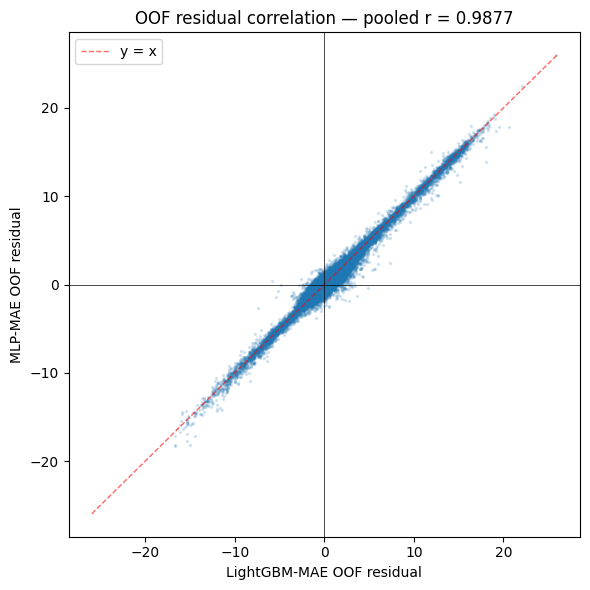


=== Decision ===
⚠️  r = 0.9877 > 0.95 — FEATURE-BOUND SATURATION.
   Halt DL track on this feature set. Redirect effort to:
     (a) feature engineering — interaction terms, lag-168, new signal types
     (b) per-(fold × series) WAPE table for fold-1 investigation
     (c) raw-sequence DL where the network sees inputs the trees never did

OOF predictions saved → /kaggle/working/oof_predictions_7a.csv


In [8]:
# Merge — the fold column must agree, sanity check that first.
joined = oof_lgbm.merge(
    oof_mlp[["series_id", "timestamp", "pred_mlp", "fold"]],
    on=["series_id", "timestamp", "fold"], how="inner",
    suffixes=("_lgbm", "_mlp"),
)
assert len(joined) == len(oof_lgbm) == len(oof_mlp), \
    "OOF row counts differ — fold splits diverged between LGBM and MLP. STOP."

joined["resid_lgbm"] = joined["target"] - joined["pred_lgbm"]
joined["resid_mlp"]  = joined["target"] - joined["pred_mlp"]

# Pearson overall
r_overall = np.corrcoef(joined["resid_lgbm"], joined["resid_mlp"])[0, 1]
# Pearson per fold
r_per_fold = []
for k in range(N_FOLDS):
    f = joined[joined["fold"] == k]
    r_per_fold.append(np.corrcoef(f["resid_lgbm"], f["resid_mlp"])[0, 1])

print("=== Pearson r(residual_LGBM, residual_MLP) ===")
print(f"{'fold':>6}  {'r':>7}")
for k, r in enumerate(r_per_fold):
    print(f"  {k:>4}    {r:>6.4f}")
print(f"  ────")
print(f"  pooled  {r_overall:>6.4f}")

# Scatter plot — first 50k points for plot speed (full set used for r computation above)
plt.figure(figsize=(6, 6))
sample = joined.sample(min(50_000, len(joined)), random_state=SEED)
plt.scatter(sample["resid_lgbm"], sample["resid_mlp"], s=2, alpha=0.15)
lim = max(joined["resid_lgbm"].abs().max(), joined["resid_mlp"].abs().max())
plt.plot([-lim, lim], [-lim, lim], "r--", lw=1, alpha=0.6, label="y = x")
plt.axhline(0, color="k", lw=0.5); plt.axvline(0, color="k", lw=0.5)
plt.xlabel("LightGBM-MAE OOF residual")
plt.ylabel("MLP-MAE OOF residual")
plt.title(f"OOF residual correlation — pooled r = {r_overall:.4f}")
plt.legend(); plt.tight_layout(); plt.show()

# Decision
print()
print("=== Decision ===")
if r_overall < R_STRONG_DIVERSITY:
    print(f"✅ r = {r_overall:.4f} < {R_STRONG_DIVERSITY} — STRONG DIVERSITY.")
    print("   Next: build LGBM+MLP blend (experiment-7c) AND proceed to TiDE (experiment-7b).")
    print("   TiDE should produce r ≤ this value, since it adds raw-sequence input.")
    DECISION = "strong_diversity"
elif r_overall > R_FEATURE_BOUND:
    print(f"⚠️  r = {r_overall:.4f} > {R_FEATURE_BOUND} — FEATURE-BOUND SATURATION.")
    print("   Halt DL track on this feature set. Redirect effort to:")
    print("     (a) feature engineering — interaction terms, lag-168, new signal types")
    print("     (b) per-(fold × series) WAPE table for fold-1 investigation")
    print("     (c) raw-sequence DL where the network sees inputs the trees never did")
    DECISION = "feature_bound"
else:
    print(f"~  r = {r_overall:.4f} — MODERATE DIVERSITY ({R_STRONG_DIVERSITY} ≤ r ≤ {R_FEATURE_BOUND}).")
    print("   Proceed to TiDE (experiment-7b). TiDE's raw-sequence input + different")
    print("   inductive bias should drive r *below* this MLP's value. Build the blend")
    print("   in experiment-7c only if either solo gain or blend gain exceeds 0.05 WAPE.")
    DECISION = "moderate_diversity"

# Save OOF predictions so experiment-7c can re-use without re-running
out_path = OUTPUT_DIR / "oof_predictions_7a.csv"
joined[["series_id", "timestamp", "target", "pred_lgbm", "pred_mlp", "fold"]].to_csv(
    out_path, index=False
)
print()
print(f"OOF predictions saved → {out_path}")


---
## §8. Simple 50/50 blend test (always run — informative even when correlation is high)

Even when `r` is high, the simple average of two models can sometimes beat either
solo because the residual variance is correlated but not identical. This section
just measures: would a naive 0.5 · LGBM + 0.5 · MLP have helped?

This is *not* the optimal blend — experiment-7c will fit weights on OOF — but it
gives a directional read.


In [9]:
print("=== Simple 50/50 blend, evaluated per fold ===")
print(f"{'fold':>6}  {'LGBM':>7}  {'MLP':>7}  {'blend':>7}  {'Δ_blend_vs_lgbm':>15}")
print("-" * 50)

per_fold_blend = []
for k in range(N_FOLDS):
    f = joined[joined["fold"] == k]
    blend = 0.5 * f["pred_lgbm"] + 0.5 * f["pred_mlp"]
    w_lgbm  = wape(f["target"], f["pred_lgbm"])
    w_mlp   = wape(f["target"], f["pred_mlp"])
    w_blend = wape(f["target"], blend)
    per_fold_blend.append(w_blend)
    print(f"  {k:>4}    {w_lgbm:>6.3f}  {w_mlp:>6.3f}  {w_blend:>6.3f}  {w_lgbm - w_blend:>+12.3f}")

blend_mean = float(np.mean(per_fold_blend))
print(f"  ────")
print(f"  mean    {LGBM_WAPE:>6.3f}  {MLP_WAPE:>6.3f}  {blend_mean:>6.3f}  "
      f"{LGBM_WAPE - blend_mean:>+12.3f}")
print()
print(f"Naive blend Δ vs LGBM solo: {LGBM_WAPE - blend_mean:+.3f}")
if LGBM_WAPE - blend_mean > 0.05:
    print(f"✅ Even a 50/50 blend improves on LGBM by > 0.05 WAPE. Optimal-weight")
    print( "   blend in experiment-7c is likely worth running regardless of r.")
elif LGBM_WAPE - blend_mean > 0:
    print(f"~  50/50 blend marginally helps. Optimal-weight blend may still pass")
    print( "   the 0.05 threshold; depends on whether MLP gets > 0.5 weight.")
else:
    print(f"✗  50/50 blend doesn't help — MLP is dragging LGBM down. Optimal-weight")
    print( "   blend would push MLP weight near 0; effectively single-model.")


=== Simple 50/50 blend, evaluated per fold ===
  fold     LGBM      MLP    blend  Δ_blend_vs_lgbm
--------------------------------------------------
     0    14.082  13.875  13.853        +0.230
     1    15.581  15.299  15.249        +0.331
     2    14.683  14.394  14.390        +0.293
  ────
  mean    14.782  14.523  14.497        +0.285

Naive blend Δ vs LGBM solo: +0.285
✅ Even a 50/50 blend improves on LGBM by > 0.05 WAPE. Optimal-weight
   blend in experiment-7c is likely worth running regardless of r.


---
## §9. Decision summary

A single table the README will be updated from once this notebook runs end-to-end.

| Quantity | Value | Notes |
|---|---|---|
| LightGBM-MAE solo CV-WAPE | filled by §4 | Must reproduce exp-5.1 ≈ 14.78 ± 0.6 |
| MLP-MAE solo CV-WAPE      | filled by §6 | Diagnostic value; not optimized for performance |
| Pearson r (LGBM, MLP) OOF residuals | filled by §7 | **The headline number** |
| 50/50 blend CV-WAPE       | filled by §8 | Lower bound on what an optimal blend could deliver |
| Decision                  | filled by §7 | `strong_diversity` / `moderate_diversity` / `feature_bound` |

### Next action depending on decision

- **`strong_diversity` (r < 0.85)**: launch experiment-7b (TiDE solo with the same
  CV) and experiment-7c (LGBM + MLP blend with OOF-fitted weights), in that order.
  TiDE should produce r ≤ this MLP's r, since TiDE adds raw-sequence inputs on top
  of a different inductive bias.

- **`moderate_diversity` (0.85 ≤ r ≤ 0.95)**: launch experiment-7b. Whether the
  blend is worth building (experiment-7c) depends on whether the §8 50/50 blend
  already cleared 0.05 WAPE — if not, MLP-only blend probably won't either, but
  TiDE might still produce decorrelated-enough residuals to be worth blending.

- **`feature_bound` (r > 0.95)**: halt the DL track *on this feature set*. The
  cheapest defensible next steps are:
  1. Per-(fold × series) WAPE table from this notebook's OOF predictions —
     identify whether fold-1 excess error concentrates in a small number of
     series, per APPROACH.md Phase 8 and exp-6 §7.
  2. Feature engineering: explicit interaction terms (`queue_pressure ×
     workload_intensity`, `queue_pressure²`), lag-168 (weekly), regime indicator
     for the fold-1 window.
  3. Raw-sequence DL (TiDE / TFT) — the network sees inputs the trees never did,
     so the feature-saturation argument doesn't bind. This is more expensive
     than (1) and (2), so it should only happen if those fail.
